In [72]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline, make_pipeline

from cuml.linear_model import LogisticRegression
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, ExtraTreesClassifier, VotingClassifier
from cuml.ensemble import RandomForestClassifier
from cuml.neighbors import KNeighborsClassifier
from cuml.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score
import cudf
import itertools

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving test.csv to test.csv
Saving train.csv to train.csv


In [ ]:
import io
import pandas as pd

# Get the list of uploaded filenames
file_names = list(uploaded.keys())

# Load the files
test_df = pd.read_csv(io.BytesIO(uploaded[file_names[0]]))
train_df = pd.read_csv(io.BytesIO(uploaded[file_names[1]]))

In [ ]:
# No of rows in train data
train_len = len(train_df)

# Concatenate train and test data
df = pd.concat([train_df, test_df], axis=0).reset_index(drop=True)

In [ ]:
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12970 entries, 0 to 12969
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   12970 non-null  object 
 1   HomePlanet    12682 non-null  object 
 2   CryoSleep     12660 non-null  object 
 3   Cabin         12671 non-null  object 
 4   Destination   12696 non-null  object 
 5   Age           12700 non-null  float64
 6   VIP           12674 non-null  object 
 7   RoomService   12707 non-null  float64
 8   FoodCourt     12681 non-null  float64
 9   ShoppingMall  12664 non-null  float64
 10  Spa           12686 non-null  float64
 11  VRDeck        12702 non-null  float64
 12  Name          12676 non-null  object 
 13  Transported   8693 non-null   object 
dtypes: float64(6), object(8)
memory usage: 1.4+ MB


In [ ]:
df.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,12700.000000,12707.000000,12681.000000,12664.000000,12686.000000,12702.000000
mean,28.771969,222.897852,451.961675,174.906033,308.476904,306.789482
std,14.387261,647.596664,1584.370747,590.558690,1130.279641,1180.097223
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,49.000000,77.000000,29.000000,57.000000,42.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [ ]:
df.describe(include=['O'])

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,VIP,Name,Transported
count,12970,12682,12660,12671,12696,12674,12676,8693
unique,12970,3,2,9825,3,2,12629,2
top,9277_01,Earth,False,G/734/S,TRAPPIST-1e,False,Artis Gambs,True
freq,1,6865,8079,8,8871,12401,2,4378


In [ ]:
df.columns

Index(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination', 'Age',
       'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck',
       'Name', 'Transported'],
      dtype='object')

In [ ]:
df["PassengerId"]

,PassengerId
0,0001_01
1,0002_01
2,0003_01
3,0003_02
4,0004_01
...,...
12965,9266_02
12966,9269_01
12967,9271_01
12968,9273_01


In [ ]:
# Extract "GroupNo" from PassengerId column
df["GroupNo"] = df["PassengerId"].str.split(pat="_", expand=True)[0].astype(int)

In [ ]:
df["GroupNo"]

,GroupNo
0,1
1,2
2,3
3,3
4,4
...,...
12965,9266
12966,9269
12967,9271
12968,9273


In [ ]:
# Find the number of members in the specific passenger's group
df["GroupSize"] = df.groupby(["GroupNo"])["GroupNo"].transform("count")

In [ ]:
df["GroupSize"]

,GroupSize
0,1
1,1
2,2
3,2
4,1
...,...
12965,2
12966,1
12967,1
12968,1


In [ ]:
df.groupby(["GroupSize"], as_index=False)["Transported"].mean()

,GroupSize,Transported
0,1,0.452445
1,2,0.53805
2,3,0.593137
3,4,0.640777
4,5,0.592453
5,6,0.614943
6,7,0.541126
7,8,0.394231


In [ ]:
# Divide group size into "Alone", "Small", "Medium" and "Large"
group_map = {1: "Alone", 2: "Small", 3: "Small", 4:"Small", 5: "Medium", 6: "Medium", 7: "Large", 8: "Large"}

df["GroupSize_grouped"] = df["GroupSize"].map(group_map)

In [ ]:
df.groupby(["GroupSize_grouped"], as_index=False)["Transported"].mean()

,GroupSize_grouped,Transported
0,Alone,0.452445
1,Large,0.495522
2,Medium,0.601367
3,Small,0.569685


In [ ]:
df.groupby(["HomePlanet"], as_index=False)["Transported"].mean()

,HomePlanet,Transported
0,Earth,0.423946
1,Europa,0.658846
2,Mars,0.523024


In [ ]:
df.groupby(["CryoSleep"], as_index=False)["Transported"].mean()

,CryoSleep,Transported
0,False,0.328921
1,True,0.817583


In [ ]:
df["CryoSleep"] = df["CryoSleep"].astype(float)

In [ ]:
df.groupby(["Destination"], as_index=False)["Transported"].mean()

,Destination,Transported
0,55 Cancri e,0.61
1,PSO J318.5-22,0.503769
2,TRAPPIST-1e,0.471175


In [ ]:
df["Cabin"].unique() #deck/num/size

array(['B/0/P', 'F/0/S', 'A/0/S', ..., 'D/296/P', 'D/297/P', 'G/1498/S'],
      dtype=object)

In [ ]:
# Extract "Deck" from Cabin column
df["Deck"] = df["Cabin"].str.split(pat="/", expand=True)[0]

In [ ]:
df["Deck"]

,Deck
0,B
1,F
2,A
3,A
4,F
...,...
12965,G
12966,NaN
12967,D
12968,D


In [ ]:
df.groupby(["Deck"], as_index=False)["Transported"].mean()

,Deck,Transported
0,A,0.496094
1,B,0.734275
2,C,0.680054
3,D,0.433054
4,E,0.357306
5,F,0.439871
6,G,0.516217
7,T,0.2


In [ ]:
# Extract "CabinNo" from Cabin column
df["CabinNo"] = df["Cabin"].str.split(pat="/", expand=True)[1]

In [ ]:
df["CabinNo"]

,CabinNo
0,0
1,0
2,0
3,0
4,1
...,...
12965,1496
12966,NaN
12967,296
12968,297


In [ ]:
df["CabinNo"] = pd.to_numeric(df["CabinNo"], errors="coerce")

In [ ]:
# Extract "CabinSize" from Cabin column
df["CabinSize"] = df["Cabin"].str.split(pat="/", expand=True)[2]

In [ ]:
df["CabinSize"]

,CabinSize
0,P
1,S
2,S
3,S
4,S
...,...
12965,S
12966,NaN
12967,P
12968,P


In [ ]:
df.groupby(["CabinSize"], as_index=False)["Transported"].mean()

,CabinSize,Transported
0,P,0.45126
1,S,0.555037


In [ ]:
df.groupby(["VIP"], as_index=False)["Transported"].mean()

,VIP,Transported
0,False,0.506332
1,True,0.38191


In [ ]:
df["VIP"] = df["VIP"].astype(float)

In [ ]:
# Create "MoneySpent" by adding all the expenses made by the passenger on RoomService, FoodCourt, ShoppingMall, Spa, VRDeck
df["MoneySpent"] = df["RoomService"] + df["FoodCourt"] + df["ShoppingMall"] + df["Spa"] + df["VRDeck"]

In [ ]:
df["MoneySpent"]

,MoneySpent
0,0.0
1,736.0
2,10383.0
3,5176.0
4,1091.0
...,...
12965,0.0
12966,1018.0
12967,0.0
12968,3203.0


<Axes: >

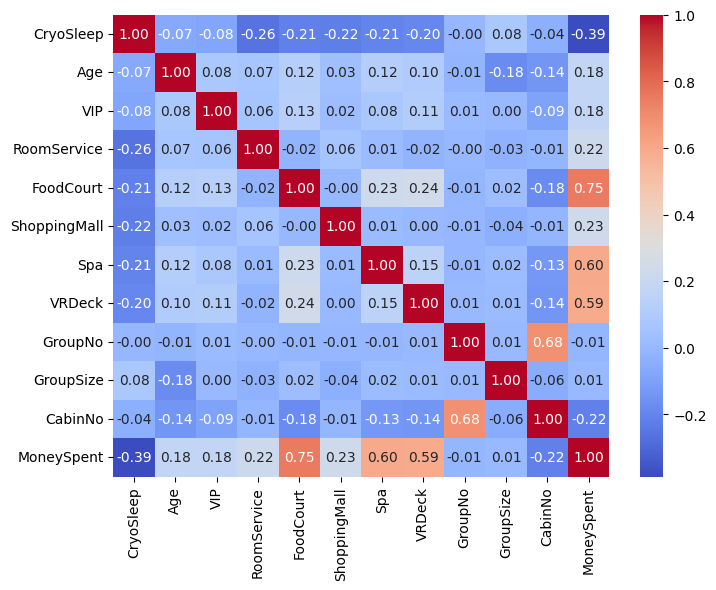

In [ ]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")

In [ ]:
train_df = df.iloc[:train_len].copy()
test_df = df.iloc[train_len:].copy()

In [ ]:
X = train_df.drop(["PassengerId", "Cabin", "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck", "Name", "GroupNo", "GroupSize", "Transported"], axis=1)
y = train_df["Transported"].astype(int)

X_test = test_df.drop(["PassengerId", "Cabin", "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck", "Name", "GroupNo", "GroupSize"], axis=1)

In [ ]:
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [ ]:
ohe_cols = ["HomePlanet", "Destination", "Deck"]
ord_cols = ["CabinSize", "GroupSize_grouped"]
num_cols = ["Age", "MoneySpent", "CabinNo", "CryoSleep", "VIP"]

In [ ]:
ohe_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("one-hot", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
])

In [ ]:
ord_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
])

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("impute", SimpleImputer(strategy="median"), num_cols),
        ("ohe_pipeline", ohe_pipeline, ohe_cols),
        ("ord_pipeline", ord_pipeline, ord_cols),
    ],
    remainder="drop",
    n_jobs=-1
)

In [ ]:
X_train_trans = preprocessor.fit_transform(X_train)
X_valid_trans = preprocessor.fit_transform(X_valid)

In [ ]:
X_train_gpu = cudf.DataFrame(X_train_trans).astype("float32")
y_train_gpu = cudf.Series(y_train).astype("int32")

X_valid_gpu = cudf.DataFrame(X_valid_trans).astype("float32")
y_valid_gpu = cudf.Series(y_valid).astype("int32")

In [ ]:
param_grid_rfc = {
    "n_estimators": [150, 200, 300, 500],
    "max_depth": [10, 13, 15, 17, 20],
    "min_samples_split": [5, 10, 15],
    "min_samples_leaf": [2, 4, 5, 6],
}

In [ ]:
best_score = 0
best_params = None
best_model_rfc = None

keys = param_grid_rfc.keys()
values = param_grid_rfc.values()
permutations = list(itertools.product(*values))

In [ ]:
for idx, perm in enumerate(permutations):
  params = dict(zip(keys, perm))

  # Initialize cuML Random Forest on GPU
  model_rfc = RandomForestClassifier(**params, random_state=42)

  # Train instantly on GPU
  model_rfc.fit(X_train_gpu, y_train_gpu)

  # Evaluate on validation set
  preds_rfc = model_rfc.predict(X_valid_gpu)
  # Convert predictions back to numpy briefly just for scoring
  score = accuracy_score(y_valid_gpu.to_numpy(), preds_rfc.to_numpy())

  if score > best_score:
    best_score = score
    best_params = params
    best_model_rfc = model_rfc

/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [12:24:25] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.8.0
  warnings.warn(py_str(msg))
/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [12:24:26] /__w/nvforest/nvforest/python/nvforest/build/cp311-abi3-linux_x86_64/_deps/treelite-src/src/serializer.cc:202: The model you are loading originated from a newer Treelite version; some functionalities may be unavailable.
Currently running Treelite version 4.6.1
The model checkpoint was generated from Treelite version 4.8.0
  warnings.warn(py_str(msg))
/usr/local/lib/python3.13/dist-packages/treelite/core.py:25: UserWarning: [12:24:26] /__w/nvforest/nvforest/python/nvforest/

In [ ]:
X_test_trans = preprocessor.transform(X_test)
X_test_gpu = cudf.DataFrame(X_test_trans).astype("float32")

In [ ]:
gpu_preds_rfc = best_model_rfc.predict(X_test_gpu)
cpu_preds_rfc = gpu_preds_rfc.to_numpy()

In [ ]:
submission = pd.DataFrame({"PassengerId": test_df["PassengerId"], "Transported": cpu_preds_rfc})
submission["Transported"] = submission["Transported"].astype(bool)
submission.to_csv("submission_rfc.csv", index=False)

In [ ]:
param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'algorithm': ['auto', 'brute'],
    'p': [1,2],
}

In [ ]:
best_score = 0
best_params = None
best_model_knn = None

keys = param_grid_knn.keys()
values = param_grid_knn.values()
permutations = list(itertools.product(*values))

In [ ]:
for idx, perm in enumerate(permutations):
  params = dict(zip(keys, perm))

  # Initialize cuML Random Forest on GPU
  model_knn = KNeighborsClassifier(**params)

  # Train instantly on GPU
  model_knn.fit(X_train_gpu, y_train_gpu)

  # Evaluate on validation set
  preds_knn = model_knn.predict(X_valid_gpu)
  # Convert predictions back to numpy briefly just for scoring
  score = accuracy_score(y_valid_gpu.to_numpy(), preds_knn.to_numpy())

  if score > best_score:
    best_score = score
    best_params = params
    best_model_knn = model_knn

In [ ]:
gpu_preds_knn = best_model_knn.predict(X_test_gpu)
cpu_preds_knn = gpu_preds_knn.to_numpy()

In [ ]:
submission = pd.DataFrame({"PassengerId": test_df["PassengerId"], "Transported": cpu_preds_knn})
submission["Transported"] = submission["Transported"].astype(bool)
submission.to_csv("submission_knn.csv", index=False)

In [81]:
param_grid_lr = {
    'C': [100,10, 1.0, 0.1, 0.001, 0.001],
}

In [82]:
best_score = 0
best_params = None
best_model_lr = None

keys = param_grid_lr.keys()
values = param_grid_lr.values()
permutations = list(itertools.product(*values))

In [83]:
for idx, perm in enumerate(permutations):
  params = dict(zip(keys, perm))

  # Initialize cuML LogisticRegression on GPU
  model_lr = LogisticRegression(**params)

  # Train directly on GPU dataframes
  model_lr.fit(X_train_gpu, y_train_gpu)

  # Evaluate on validation GPU dataframes
  preds_lr = model_lr.predict(X_valid_gpu)
  score = accuracy_score(y_valid_gpu.to_numpy(), preds_lr.to_numpy())

  if score > best_score:
    best_score = score
    best_params = params
    best_model_lr = model_lr

In [84]:
gpu_preds_lr = best_model_lr.predict(X_test_gpu)
cpu_preds_lr = gpu_preds_lr.to_numpy()

In [85]:
submission = pd.DataFrame({"PassengerId": test_df["PassengerId"], "Transported": cpu_preds_lr})
submission["Transported"] = submission["Transported"].astype(bool)
submission.to_csv("submission_lr.csv", index=False)